# Feasible Regions and Linear Programming with PuLP

<div class="alert alert-block alert-success"><b>Problem 1:</b> Graph the feasible region for the system of inequalities. Tell
whether the region is bounded or unbounded.
    <br>x + y ≤ 5
    <br>x − y ≤ − 2
    <br>6x + y ≥ 0
    <br>
    <br></div>



<div class="alert alert-block alert-info"><b>Note:</b> The corners of the feasible regions below are found with <i>linalg.solve</i> from the <i>numpy</i> library. For example, to <i>solve</i> for x0 and x1 in the system of equations 3 * x0 + x1 = 9 and x0 + 2 * x1 = 8, you would set it up as follows:
    
<code>
>>> a = np.array([[3,1], [1,2]])
>>> b = np.array([9,8])
>>> x = np.linalg.solve(a, b)
>>> x
array([2.,  3.])

</code>
   For more details see: https://numpy.org/doc/stable/reference/generated/numpy.linalg.solve.html
</div>

In [1]:
%matplotlib inline

import matplotlib.pyplot 
from matplotlib.pyplot import *
import numpy 
import numpy as np
from numpy import arange

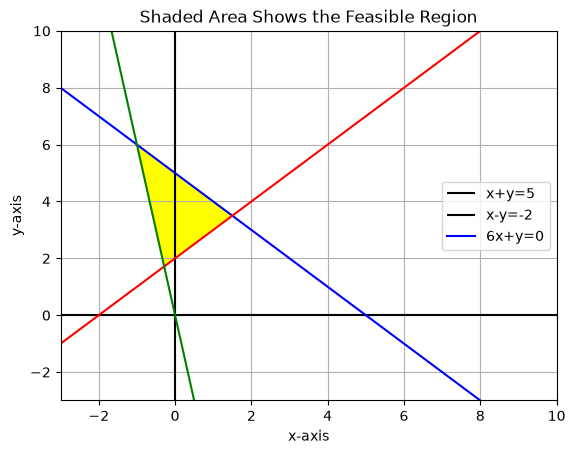

Corners: [(1.5, 3.5), (-1.0, 6.0), (-0.286, 1.714)]
The region is a triangle, so it is bounded.


In [2]:
figure()
x= arange(-3,10.1,0.1)
y1= 5-x
y2= x+2
y3=-6*x

xlim(-3,10)
ylim(-3,10)
hlines(0,-3,10,color='k')
vlines(0,-3,10,color='k')
grid(True)

xlabel('x-axis')
ylabel('y-axis')
title ('Shaded Area Shows the Feasible Region')

plot(x,y1,color='b')
plot(x,y2,color='r')
plot(x,y3,color='g')
legend(['x+y=5','x-y=-2','6x+y=0'])
# Matplotlib fills a polygon when it is given the corners in order.

# linalg.solve to find the points of intersection
# https://docs.scipy.org/doc/numpy/reference/generated/numpy.linalg.solve.html
a1 = np.array([[1,1], [1,-1]])
b1 = np.array([5,-2])
c1 = np.linalg.solve(a1, b1)

a2 = np.array([[1,1], [6, 1]])
b2 = np.array([5,0])
c2 = np.linalg.solve(a2, b2)

a3 = np.array([[1,-1], [6,1]])
b3 = np.array([-2,0])
c3 = np.linalg.solve(a3, b3)

# Matplotlib colors
# https://matplotlib.org/examples/color/named_colors.html

x= [c1[0], c2[0], c3[0]]
y= [c1[1], c2[1], c3[1]]
fill(x,y,color="yellow")
show()
print("Corners:", [tuple(np.round(c, 3)) for c in (c1, c2, c3)])
print("The region is a triangle, so it is bounded.")

<div class="alert alert-block alert-success"><b>Problem 2: </b>A company produces handmade shawls and afghans. They spin the yarn, dye it, and then weave it. A shawl requires 1 hour of spinning, 1 hour of dyeing, and 1 hour of weaving. An afghan requires 1 hour of spinning, 4 hours of dyeing, and 2 hours of weaving. There are at most 7 hours available each day for spinning, 12 hours for dyeing, and 8 hours for weaving. Graph the feasible region</div>

<div class="alert alert-block alert-info"><b>Solution:</b>Let x be the number of shawls and y be the number of afghans. <br><br>The system of inequalities is as shown below:<br>
    x + y ≤ 7 <br>
x + 4y ≤ 12 <br>
x + 2y ≤ 8 <br>

</div>

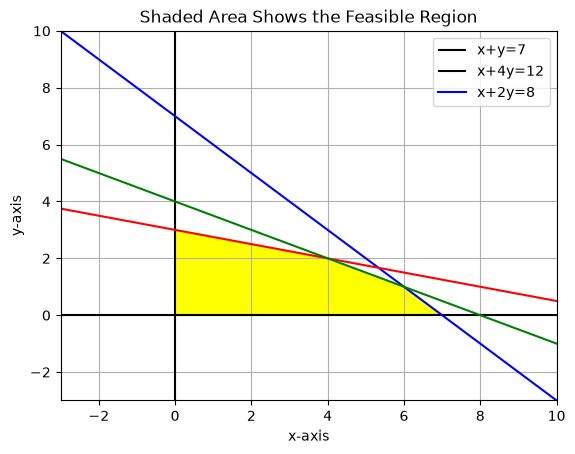

In [3]:
figure()
x= arange(-3,10.1,0.1)
y1= 7-x
y2= (12-x)/4
y3= (8-x)/2 

xlim(-3,10)
ylim(-3,10)
hlines(0,-3,10,color='k')
vlines(0,-3,10,color='k')
grid(True)

xlabel('x-axis')
ylabel('y-axis')
title ('Shaded Area Shows the Feasible Region')

plot(x,y1,color='b')
plot(x,y2,color='r')
plot(x,y3,color='g')
legend(['x+y=7','x+4y=12','x+2y=8'])

# linalg.solve to find the points of intersection
# https://docs.scipy.org/doc/numpy/reference/generated/numpy.linalg.solve.html
a1 = np.array([[1,4], [1,0]])
b1 = np.array([12,0])
c1 = np.linalg.solve(a1, b1)

a2 = np.array([[1,4], [1, 2]])
b2 = np.array([12,8])
c2 = np.linalg.solve(a2, b2)

a3 = np.array([[1,1], [1,2]])
b3 = np.array([7,8])
c3 = np.linalg.solve(a3, b3)

a4 = np.array([[1,1], [0,1]])
b4 = np.array([7,0])
c4 = np.linalg.solve(a4, b4)


# Matplotlib colors
# https://matplotlib.org/examples/color/named_colors.html

x= [c1[0], c2[0], c3[0], c4[0], 0]
y= [c1[1], c2[1], c3[1], c4[1], 0]
fill(x,y,color="yellow")
show()

<div class="alert alert-block alert-success"><b>Problem 4: </b>Solve the following linear programming problem.
<br>Maximize: z = 10x + 12y
<br>subject to: 3x + 8y ≤ 24
<br>10x + y ≤ 24
x ≥ 0, y ≥ 0
</div>

In [4]:
import pulp as p

In [5]:
from pulp import LpVariable, LpProblem, LpMaximize, LpStatus, value, LpMinimize

# declare your variables
x = LpVariable("x", 0, None) # x>=0
y = LpVariable("y", 0, None) # y>=0

# defines the problem
prob = LpProblem("problem", LpMaximize)

# defines the constraints
prob += 3*x + 8*y <= 24
prob += 10*x + y <= 24

# defines the objective function to maximize
prob += 10*x + 12*y

# solve the problem
status = prob.solve(p.PULP_CBC_CMD(msg=0))
LpStatus[status]

print("The maximum occurs at the point (", round(value(x), 4), ",", round(value(y), 4), ")")
print("Maximum value is", round(value(prob.objective), 4))

The maximum occurs at the point ( 2.1818 , 2.1818 )
Maximum value is 48.0


<div class="alert alert-block alert-success"><b>Problem 6:</b>
A patient takes vitamin pills. Each day he must have at least 180 IU of vitamin A, 4 mg of vitamin B1, and 140 mg of vitamin
C. He can choose between pill 1, which contains 90 IU of vitamin A, 1 mg of vitamin B1, and 20 mg of vitamin C, and pill 2,
which contains 30 IU of vitamin A, 1 mg of vitamin B1 , and 50 mg of vitamin C. Pill 1 costs 30 cents, and pill 2 costs 15 cents. How many of each pill should he buy in order to minimize his cost?
</div>

<div class="alert alert-block alert-info">Let <b>p1</b> and <b>p2</b> be the number of pill 1 and pill 2 taken each day. <br/>
    
Minimize: c = 30p1 + 15p2 <br>
subject to: 90p1 + 30p2 ≥ 180 <br>
p1 + p2 ≥ 4 <br>
20p1 + 50p2 ≥ 140 <br>
p1 ≥ 0, p2 ≥ 0 <br>
</div>

In [6]:
from pulp import LpVariable, LpProblem, LpMaximize, LpStatus, value, LpMinimize

# declare your variables
p1 = LpVariable("p1", 0, None) # p1>=0
p2 = LpVariable("p2", 0, None) # p2>=0

# defines the problem
prob = LpProblem("problem", LpMinimize)

# defines the constraints
prob += 90*p1 + 30*p2 >= 180   # vitamin A
prob += p1 + p2 >= 4           # vitamin B1
prob += 20*p1 + 50*p2 >= 140   # vitamin C

# defines the objective function to minimize (cents)
prob += 30*p1 + 15*p2

# solve the problem
status = prob.solve(p.PULP_CBC_CMD(msg=0))
LpStatus[status]

print("Pill 1:", value(p1), " Pill 2:", value(p2))
print("The minimum cost is", value(prob.objective), "cents")

Pill 1: 1.0  Pill 2: 3.0
The minimum cost is 75.0 cents


<div class="alert alert-block alert-success"><b> Problem 15.</b>
A company's lawn seed mixtures contain three types of seeds: bluegrass, rye, and Bermuda. The costs per pound of the
three types are 11 cents, 14 cents, and 6 cents, respectively. In each batch there must be at least 20% bluegrass seed
and the amount of Bermuda must be no more than two-thirds the amount of rye. To fill current orders the company must
make at least 9000 pounds of the mixture. How much of each kind of seed should be used to minimize cost?    
</div>

<div class="alert alert-block alert-info">
   **Solution:**Let x be the pounds of bluegrass seed <br>
Let y be the pounds of rye seed <br>
Let z be the pounds of Bermuda seed <br>

Cost to be minimized = 0.11 x + 0.14 y + 0.06 z <br>
Subject to:
* x ≥ 0.20(x + y + z) 
* z ≤ 2/3 y 
* x + y + z ≥ 9000 
* x ≥ 0 y ≥ 0 z ≥ 0 
 
</div>

In [7]:
from pulp import LpVariable, LpProblem, LpMaximize, LpStatus, value, LpMinimize

model = LpProblem("problem", LpMinimize)
x = LpVariable("x", 0, None) # bluegrass, x >= 0
y = LpVariable("y", 0, None) # rye, y >= 0
z = LpVariable("z", 0, None) # Bermuda, z >= 0

model += x >= 0.20*(x + y + z)
model += z <= (2/3)*y
model += x + y + z >= 9000

model += 0.11*x + 0.14*y + 0.06*z

# solve the problem
status = model.solve(p.PULP_CBC_CMD(msg=0))
LpStatus[status]

print('Pounds of Bluegrass to be used = {:.2f}'.format(value(x)))
print('Pounds of Rye to be used = {:.2f}'.format(value(y)))
print('Pounds of Bermuda to be used = {:.2f}'.format(value(z)))
print('Minimum Cost is ${:.2f}'.format(value(model.objective)))

Pounds of Bluegrass to be used = 1800.00
Pounds of Rye to be used = 4320.00
Pounds of Bermuda to be used = 2880.00
Minimum Cost is $975.60
